<a href="https://colab.research.google.com/github/deva123932/CSA-4703-DEEP-LEARNING/blob/main/exp_29.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1: Build and Train a Variational Autoencoder (VAE) on Fashion-MNIST

In this section, we build a VAE with an encoder, a reparameterization layer, and a decoder. We train it using a combination of reconstruction loss and KL-divergence loss.

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models, losses
import numpy as np
import matplotlib.pyplot as plt

# Load and preprocess Fashion-MNIST
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)

# Reparameterization sampling layer
class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = tf.keras.backend.random_normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

# Encoder
latent_dim = 2
encoder_inputs = layers.Input(shape=(28, 28, 1))
x = layers.Conv2D(32, 3, activation='relu', strides=2, padding='same')(encoder_inputs)
x = layers.Conv2D(64, 3, activation='relu', strides=2, padding='same')(x)
x = layers.Flatten()(x)
x = layers.Dense(16, activation='relu')(x)
z_mean = layers.Dense(latent_dim, name='z_mean')(x)
z_log_var = layers.Dense(latent_dim, name='z_log_var')(x)
z = Sampling()([z_mean, z_log_var])
encoder = models.Model(encoder_inputs, [z_mean, z_log_var, z], name='encoder')

# Decoder
latent_inputs = layers.Input(shape=(latent_dim,))
x = layers.Dense(7 * 7 * 64, activation='relu')(latent_inputs)
x = layers.Reshape((7, 7, 64))(x)
x = layers.Conv2DTranspose(64, 3, activation='relu', strides=2, padding='same')(x)
x = layers.Conv2DTranspose(32, 3, activation='relu', strides=2, padding='same')(x)
decoder_outputs = layers.Conv2DTranspose(1, 3, activation='sigmoid', padding='same')(x)
decoder = models.Model(latent_inputs, decoder_outputs, name='decoder')

# VAE Model class
class VAE(models.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super(VAE, self).__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = tf.keras.metrics.Mean(name='total_loss')
        self.reconstruction_loss_tracker = tf.keras.metrics.Mean(name='reconstruction_loss')
        self.kl_loss_tracker = tf.keras.metrics.Mean(name='kl_loss')

    @property
    def metrics(self):
        return [self.total_loss_tracker, self.reconstruction_loss_tracker, self.kl_loss_tracker]

    def train_step(self, data):
        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data)
            reconstruction = self.decoder(z)
            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(
                    losses.binary_crossentropy(data, reconstruction), axis=(1, 2)
                )
            )
            kl_loss = -0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var))
            kl_loss = tf.reduce_mean(tf.reduce_sum(kl_loss, axis=1))
            total_loss = reconstruction_loss + kl_loss
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {
            'loss': self.total_loss_tracker.result(),
            'reconstruction_loss': self.reconstruction_loss_tracker.result(),
            'kl_loss': self.kl_loss_tracker.result(),
        }

vae = VAE(encoder, decoder)
vae.compile(optimizer=tf.keras.optimizers.Adam())
vae.fit(x_train, epochs=10, batch_size=128)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 84s 172ms/step - kl_loss: 4.4667 - loss: 362.8465 - reconstruction_loss: 358.3799
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 76s 162ms/step - kl_loss: 5.5707 - loss: 319.2813 - reconstruction_loss: 313.7105
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 77s 164ms/step - kl_loss: 5.3189 - loss: 310.7926 - reconstruction_loss: 305.4737
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 82s 163ms/step - kl_loss: 5.1469 - loss: 307.2552 - reconstruction_loss: 302.1084
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 78s 166ms/step - kl_loss: 5.0470 - loss: 305.0032 - reconstruction_loss: 299.9561
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 82s 166ms/step - kl_loss: 4.9406 - loss: 303.4715 - reconstruction_loss: 298.5309
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 78s 166ms/step - kl_loss: 4.9077 - loss:

# Task 2: Generate Images by Sampling Latent Space & Plot 2-D Grid

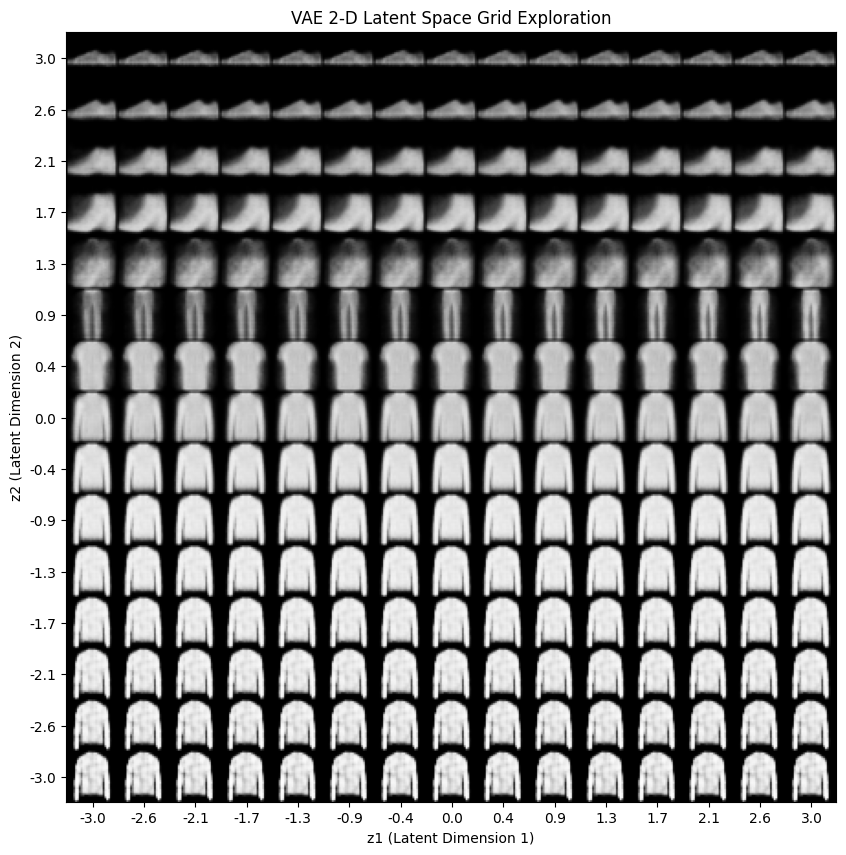

In [2]:
def plot_latent_space_grid(n=15, digit_size=28):
    figure = np.zeros((digit_size * n, digit_size * n))
    grid_x = np.linspace(-3.0, 3.0, n)
    grid_y = np.linspace(-3.0, 3.0, n)[::-1]

    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):
            z_sample = np.array([[xi, yi]])
            x_decoded = vae.decoder.predict(z_sample, verbose=0)
            digit = x_decoded[0].reshape(digit_size, digit_size)
            figure[
                i * digit_size : (i + 1) * digit_size,
                j * digit_size : (j + 1) * digit_size,
            ] = digit

    plt.figure(figsize=(10, 10))
    start_range = digit_size // 2
    end_range = n * digit_size + start_range
    pixel_range = np.arange(start_range, end_range, digit_size)
    sample_range_x = np.round(grid_x, 1)
    sample_range_y = np.round(grid_y, 1)
    plt.xticks(pixel_range, sample_range_x)
    plt.yticks(pixel_range, sample_range_y)
    plt.xlabel("z1 (Latent Dimension 1)")
    plt.ylabel("z2 (Latent Dimension 2)")
    plt.imshow(figure, cmap='Greys_r')
    plt.title("VAE 2-D Latent Space Grid Exploration")
    plt.show()

plot_latent_space_grid(n=15)

# Task 3 & 4: Build a DCGAN, Train, and Save Generated Images Every Few Epochs

In [3]:
# Rescale images to [-1, 1] for GAN training
x_train_gan = (x_train * 2.0) - 1.0
latent_dim_gan = 100

def build_generator():
    model = models.Sequential([
        layers.Dense(7 * 7 * 128, input_dim=latent_dim_gan),
        layers.Reshape((7, 7, 128)),
        layers.Conv2DTranspose(128, 4, strides=2, padding='same', activation='relu'),
        layers.Conv2DTranspose(64, 4, strides=2, padding='same', activation='relu'),
        layers.Conv2D(1, 7, padding='same', activation='tanh')
    ])
    return model

def build_discriminator():
    model = models.Sequential([
        layers.Conv2D(64, 3, strides=2, padding='same', input_shape=(28, 28, 1)),
        layers.LeakyReLU(0.2),
        layers.Dropout(0.3),
        layers.Conv2D(128, 3, strides=2, padding='same'),
        layers.LeakyReLU(0.2),
        layers.Dropout(0.3),
        layers.Flatten(),
        layers.Dense(1, activation='sigmoid')
    ])
    return model

generator = build_generator()
discriminator = build_discriminator()

discriminator.compile(loss='binary_crossentropy', optimizer=tf.keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5))
discriminator.trainable = False

gan_input = layers.Input(shape=(latent_dim_gan,))
gan_output = discriminator(generator(gan_input))
gan = models.Model(gan_input, gan_output)
gan.compile(loss='binary_crossentropy', optimizer=tf.keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5))

def save_and_plot_images(epoch, generator, examples=16, dim=(4, 4), figsize=(5, 5)):
    noise = np.random.normal(0, 1, size=[examples, latent_dim_gan])
    generated_images = generator.predict(noise, verbose=0)
    generated_images = generated_images.reshape(examples, 28, 28)
    plt.figure(figsize=figsize)
    for i in range(generated_images.shape[0]):
        plt.subplot(dim[0], dim[1], i+1)
        plt.imshow((generated_images[i] + 1.0) / 2.0, cmap='gray_r')
        plt.axis('off')
    plt.tight_layout()
    plt.suptitle(f'Generated Images - Epoch {epoch}')
    plt.show()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


# Task 5: Train the GAN and Plot Loss Curves

/usr/local/lib/python3.13/dist-packages/keras/src/backend/tensorflow/trainer.py:86: UserWarning: The model does not have any trainable weights.
  warnings.warn("The model does not have any trainable weights.")


Epoch 1/15 | Discriminator Loss: 1.0623 | Generator Loss: 0.2992


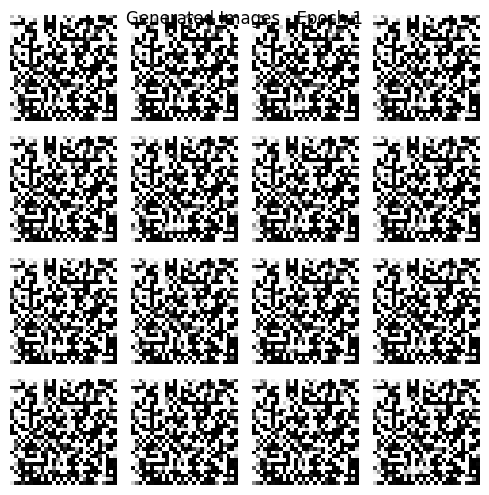

Epoch 2/15 | Discriminator Loss: 1.1619 | Generator Loss: 0.2357
Epoch 3/15 | Discriminator Loss: 1.2003 | Generator Loss: 0.2126


In [ ]:
epochs = 15
batch_size = 128
batches = x_train_gan.shape[0] // batch_size

d_losses = []
g_losses = []

for epoch in range(1, epochs + 1):
    for batch in range(batches):
        # Real images
        image_batch = x_train_gan[np.random.randint(0, x_train_gan.shape[0], size=batch_size)]
        # Fake images
        noise = np.random.normal(0, 1, size=[batch_size, latent_dim_gan])
        generated_images = generator.predict(noise, verbose=0)

        # Labels
        real_labels = np.ones((batch_size, 1)) * 0.9  # Label smoothing
        fake_labels = np.zeros((batch_size, 1))

        # Train discriminator
        d_loss_real = discriminator.train_on_batch(image_batch, real_labels)
        d_loss_fake = discriminator.train_on_batch(generated_images, fake_labels)
        d_loss = 0.5 * np.add(d_loss_real, d_loss_fake)

        # Train generator
        noise = np.random.normal(0, 1, size=[batch_size, latent_dim_gan])
        g_loss = gan.train_on_batch(noise, np.ones((batch_size, 1)))

    d_losses.append(d_loss)
    g_losses.append(g_loss)
    print(f"Epoch {epoch}/{epochs} | Discriminator Loss: {d_loss:.4f} | Generator Loss: {g_loss:.4f}")

    if epoch % 5 == 0 or epoch == 1:
        save_and_plot_images(epoch, generator)

# Plot the training loss curves
plt.figure(figsize=(10, 5))
plt.plot(d_losses, label='Discriminator Loss')
plt.plot(g_losses, label='Generator Loss')
plt.title('GAN Training Loss Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()